# R3: Geometry checks

**Goal:** check every field polygon: is it valid, is its size sensible, is it in the right place,
and does it overlap other fields? Every problem gets its own flag column. Nothing is deleted here.

**Input:** `data/processed_v2/R2_merged.gpkg` (from R2). All distances and areas are measured
in EPSG:32643 (UTM zone 43N, metres).

## Step 1: Repair broken polygons

A broken (invalid) polygon has lines that cross themselves, so its area and shape cannot be trusted.
We compare two common repairs: `make_valid` (keeps every piece of the shape) and `buffer(0)`
(can quietly drop pieces). We use `make_valid` and flag any repair that changes the area by more than 1%.

**Found:** 2 broken polygons, both in 2025. After `make_valid`, all polygons are valid. One keeps
its area (7,295 m²). The other changes by 4.5% (2,987 to 3,122 m²); `buffer(0)` gives only
3,055 m² because it drops a piece, so `make_valid` is used. That field is flagged.
1 field (2025) has no polygon and is flagged.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import MultiPolygon, Polygon, GeometryCollection

here = Path.cwd()
ROOT = here if (here / "data" / "raw").exists() else here.parent
DATA2 = ROOT / "data" / "processed_v2"
OUT = ROOT / "results" / "phase1a"
UTM = 32643  # WGS 84 / UTM zone 43N: distances and areas in metres

f = gpd.read_file(DATA2 / "R2_merged.gpkg").to_crs(UTM)
print("fields:", len(f), "| missing polygons:", int(f.geometry.isna().sum()))

def polygons_only(g):
    """make_valid can return a mix of shapes; keep only the polygon parts."""
    if g is None or g.is_empty:
        return g
    if isinstance(g, (Polygon, MultiPolygon)):
        return g
    if isinstance(g, GeometryCollection):
        parts = []
        for p in g.geoms:
            if isinstance(p, Polygon):
                parts.append(p)
            elif isinstance(p, MultiPolygon):
                parts.extend(p.geoms)
        return MultiPolygon(parts) if len(parts) > 1 else (parts[0] if parts else None)
    return None

has = f.geometry.notna()
f["geom_valid_raw"] = f.geometry.is_valid.where(has)
f["area_m2_before"] = f.geometry.area.where(has)

bad = has & ~f.geometry.is_valid
f["area_m2_buffer0"] = f.geometry.buffer(0).area.where(bad)   # the other common repair, for comparison
f.loc[bad, "geometry"] = f.loc[bad, "geometry"].make_valid().apply(polygons_only)
f["area_m2_after"] = f.geometry.area.where(has)
f["repair_area_change_pct"] = (100 * (f["area_m2_after"] - f["area_m2_before"]) / f["area_m2_before"]).where(bad)
f["flag_geom_repaired"] = bad
f["flag_repair_changed_area"] = bad & (f["repair_area_change_pct"].abs() > 1)
f["flag_no_polygon"] = ~has

rep = f.loc[bad, ["year", "batch", "area_m2_before", "area_m2_after", "area_m2_buffer0", "repair_area_change_pct"]].round(1)
rep.to_csv(OUT / "R3_repairs.csv", index=False)
print("\ninvalid polygons repaired:", int(bad.sum()))
print(rep.to_string(index=False))
print("\nall polygons valid now:", bool(f.loc[has, "geometry"].is_valid.all()))
print("repairs that changed the area by more than 1%:", int(f["flag_repair_changed_area"].sum()))

fields: 1207 | missing polygons: 1

invalid polygons repaired: 2
 year batch  area_m2_before  area_m2_after  area_m2_buffer0  repair_area_change_pct
 2025  2025          2986.9         3122.1           3054.5                     4.5
 2025  2025          7295.2         7295.2           7295.2                     0.0

all polygons valid now: True
repairs that changed the area by more than 1%: 1


## Step 2: Slivers and field size

**(a) Slivers.** Some fields are drawn in several pieces. Pieces smaller than one Sentinel-1 pixel
(10 m x 10 m = 100 m²) are drawing mistakes, so they are removed. Bigger pieces are real parts
of a split field and are kept. Note: the GeoPackage stores every field as MultiPolygon,
so we count the pieces instead of reading the shape type.

**(b) Field size.** Field areas are skewed, so we use log10(area) and flag fields below
Q1 - 3 IQR (tiny) or above Q3 + 3 IQR (huge).

**Found:** 7 multi-part fields (the 6 from R1, plus the repaired 2025 field). Slivers of 0.7 to
91 m² were removed from 6 of them; 4 fields stay split into 2 real pieces and are flagged.
Field sizes range from 0.26 to 17.8 acres (median 2.1). The cut-offs are 0.17 to 31.3 acres,
so no field is tiny or huge. Every field is larger than 10 Sentinel-1 pixels (1,000 m²).

In [3]:
PIXEL_M2 = 100   # one Sentinel-1 pixel at 10 m x 10 m

# (a) multi-part fields: drop pieces smaller than one pixel (drawing slivers), keep real pieces
def drop_slivers(g):
    if isinstance(g, MultiPolygon):
        keep = [p for p in g.geoms if p.area >= PIXEL_M2]
        return MultiPolygon(keep)
    return g

# note: the GeoPackage stores every field as MultiPolygon, so we count the pieces, not the type
f["n_parts_raw"] = f.geometry.apply(lambda g: len(g.geoms) if isinstance(g, MultiPolygon) else (1 if g is not None else 0))
multi = f["n_parts_raw"] > 1
f["sliver_area_m2"] = 0.0
f.loc[multi, "sliver_area_m2"] = f.loc[multi, "geometry"].apply(lambda g: sum(p.area for p in g.geoms if p.area < PIXEL_M2))
f.loc[multi, "geometry"] = f.loc[multi, "geometry"].apply(drop_slivers)
f["n_parts"] = f.geometry.apply(lambda g: len(g.geoms) if isinstance(g, MultiPolygon) else (1 if g is not None else 0))
f["flag_slivers_removed"] = f["sliver_area_m2"] > 0
f["flag_split_field"] = f["n_parts"] > 1

parts = f.loc[multi, ["year", "n_parts_raw", "n_parts", "sliver_area_m2"]].round(1)
print("multi-part fields:", int(multi.sum()))
print(parts.to_string(index=False))

# (b) field size: outliers on log10(area), Q1 - 3 IQR and Q3 + 3 IQR
f["area_m2"] = f.geometry.area.where(f.geometry.notna())
la = np.log10(f["area_m2"])
q1, q3 = la.quantile([0.25, 0.75]); iqr = q3 - q1
lo, hi = 10 ** (q1 - 3 * iqr), 10 ** (q3 + 3 * iqr)
f["flag_tiny"] = f["area_m2"] < lo
f["flag_huge"] = f["area_m2"] > hi

a = f["area_m2"] / 4046.8564224   # acres, for reading only
print(f"\nfield area (acres): min {a.min():.2f} | Q1 {a.quantile(.25):.2f} | median {a.median():.2f} | "
      f"Q3 {a.quantile(.75):.2f} | max {a.max():.2f}")
print(f"cut-offs on log-area (Q1 - 3 IQR, Q3 + 3 IQR): {lo:,.0f} m2 to {hi:,.0f} m2 "
      f"({lo/4046.86:.2f} to {hi/4046.86:.1f} acres)")
print("tiny fields:", int(f["flag_tiny"].sum()), "| huge fields:", int(f["flag_huge"].sum()))
print("fields smaller than 10 pixels (1,000 m2):", int((f["area_m2"] < 1000).sum()))
f.loc[f["flag_tiny"] | f["flag_huge"], ["year", "batch", "area_m2"]].round(0).to_csv(OUT / "R3_size_outliers.csv", index=False)

multi-part fields: 7
 year  n_parts_raw  n_parts  sliver_area_m2
 2023            2        2             0.0
 2023            3        2             0.7
 2023            3        1            11.0
 2023            2        1            91.0
 2024            3        2            54.0
 2024            5        1            39.5
 2025            3        2            67.6

field area (acres): min 0.26 | Q1 1.58 | median 2.12 | Q3 3.33 | max 17.77
cut-offs on log-area (Q1 - 3 IQR, Q3 + 3 IQR): 680 m2 to 126,707 m2 (0.17 to 31.3 acres)
tiny fields: 0 | huge fields: 0
fields smaller than 10 pixels (1,000 m2): 0


## Step 3: Field area and the recorded area columns

We compute each field's area from its polygon in UTM (`area_acres`); this becomes the area we use.
First we check that UTM area is accurate here, against a true equal-area projection.
Then each recorded area is divided by our area. The ratio tells the unit: near 1 = acres,
near 0.405 = hectares, near 40 = guntha (1/40 acre), near 4,047 = m². We pick the closest unit
for every field and check if it agrees within 20%. Farmer areas that match in no unit are flagged.

**Found:** UTM area agrees with the equal-area projection (median ratio 0.9999), so it is used
for every field. All recorded areas are in acres. The provider's acre column matches our area for
798 fields; 26 do not (7 negative, 19 far off). The provider's m² column is 5.9% larger than the
true area for every field, which is not a projection effect, so it is not used. The farmer's
planned area matches within 20% for 334 of 381 fields, and the actual area for 280 of 353.
71 of 353 farmer areas match the polygon in no unit and are flagged.

In [4]:
ACRE = 4046.8564224
f["area_acres"] = f["area_m2"] / ACRE          # our area: from the polygon, in UTM

# check that UTM area is exact enough: compare with a true equal-area projection
ea = f.to_crs(6933).geometry.area
print(f"UTM area vs equal-area projection (EPSG:6933): median ratio {(f['area_m2'] / ea).median():.4f}")

# what each recorded area would be, as a ratio to our polygon area in acres.
# if the unit is acres the ratio is near 1; hectares near 0.405; guntha (1/40 acre) near 40; m2 near 4047
UNITS = {"acres": 1.0, "hectares": 1 / 2.4710538, "guntha": 40.0, "m2": ACRE}
recorded = {"area_acres_provider": f["area_acres_provider"],
            "area_m2_provider (as acres)": f["area_m2_provider"] / ACRE,
            "area_planned_farmer": f["area_planned_farmer"],
            "area_actual_farmer": f["area_actual_farmer"]}

def best_unit(ratio):
    """Unit whose factor is closest to the ratio (on a log scale), and whether it is within 20%."""
    if pd.isna(ratio) or ratio <= 0:
        return pd.Series({"unit": "no value" if pd.isna(ratio) else "zero or negative", "within_20pct": False})
    name, fac = min(UNITS.items(), key=lambda kv: abs(np.log(ratio / kv[1])))
    return pd.Series({"unit": name, "within_20pct": abs(ratio / fac - 1) <= 0.2})

rows = []
for col, v in recorded.items():
    r = v / f["area_acres"]
    res = r.apply(best_unit)
    ok = v.notna()
    f[f"ratio_{col.split(' ')[0]}"] = r
    f[f"unit_{col.split(' ')[0]}"] = res["unit"].where(ok)
    f[f"within20_{col.split(' ')[0]}"] = res["within_20pct"].where(ok)
    for (unit, w), n in res[ok].value_counts(["unit", "within_20pct"]).items():
        rows.append({"column": col, "best_unit": unit, "within_20pct": w, "fields": int(n)})
    print(f"{col:28} n={int(ok.sum()):4}  median ratio {r[ok & (r > 0)].median():.3f}")

units = pd.DataFrame(rows).sort_values(["column", "fields"], ascending=[True, False])
units.to_csv(OUT / "R3_area_units.csv", index=False)
print("\n" + units.to_string(index=False))

# flag: the farmer's actual area does not match the polygon in any unit (within 20%)
f["flag_area_mismatch"] = f["area_actual_farmer"].notna() & (f["within20_area_actual_farmer"] == False)
f["flag_provider_area_negative"] = f["area_acres_provider"] <= 0
print("\nfarmer area does not match the polygon in any unit:", int(f["flag_area_mismatch"].sum()),
      "of", int(f["area_actual_farmer"].notna().sum()))

UTM area vs equal-area projection (EPSG:6933): median ratio 0.9999
area_acres_provider          n= 826  median ratio 1.000
area_m2_provider (as acres)  n= 381  median ratio 1.059
area_planned_farmer          n= 381  median ratio 1.016
area_actual_farmer           n= 353  median ratio 1.019

                     column        best_unit  within_20pct  fields
        area_acres_provider            acres          True     798
        area_acres_provider            acres         False      10
        area_acres_provider         hectares         False       9
        area_acres_provider zero or negative         False       7
        area_acres_provider         hectares          True       1
        area_acres_provider         no value         False       1
         area_actual_farmer            acres          True     280
         area_actual_farmer            acres         False      65
         area_actual_farmer         hectares         False       4
         area_actual_farmer           

## Step 4: Location against the real boundaries

Each field's point (inside its polygon) is checked against Latur's district and taluka boundaries.
GADM 4.1 has only 5 of Latur's 10 talukas (an older map), so we use DataMeet's village boundaries
(Census 2001, ODbL licence), joined by taluka into all 10 talukas. GADM is kept only to compare
the district check. A point in a small gap between villages takes the nearest taluka.

**Found:** 2 fields are outside the district (0.19 and 2.06 km); GADM's rougher line gives 5.
46 fields sit in a different taluka from the recorded one. 7 are the "Jalkot" fields, which are
really in Latur taluka (confirms R1). Of the other 39, 21 are within 1 km of their recorded taluka
(likely boundary precision) and 9 are more than 10 km away (clearly wrong labels).

In [6]:
BND = ROOT / "data" / "boundaries"
SRC = BND / "latur_boundaries_2001.gpkg"   # built from DataMeet village boundaries (Census 2001), ODbL
district = gpd.read_file(SRC, layer="latur_district").to_crs(UTM)
talukas = gpd.read_file(SRC, layer="latur_talukas").to_crs(UTM)
print("talukas:", sorted(talukas["SUB_DIST"]), f"| district area {district.area.sum() / 1e6:,.0f} km2")

pt = f[f.geometry.notna()].copy()
pt["geometry"] = pt.geometry.representative_point()

# (a) inside the district?
dist_geom = district.geometry.union_all()
f["km_outside_district"] = (pt.geometry.distance(dist_geom) / 1000).round(2)
f["flag_outside_district"] = f["km_outside_district"] > 0

# for comparison: the same check with the GADM district line
try:
    gadm2 = gpd.read_file(next(BND.rglob("gadm41_IND_2.shp")))
    gd = gadm2[(gadm2["NAME_1"] == "Maharashtra") & (gadm2["NAME_2"] == "Latur")].to_crs(UTM).geometry.union_all()
    print("outside the district: DataMeet", int(f["flag_outside_district"].sum()),
          "| GADM", int((pt.geometry.distance(gd) > 0).sum()))
except StopIteration:
    print("GADM file not found, comparison skipped")

# (b) which taluka is the field really in? (points in a small gap between villages take the nearest taluka)
j = gpd.sjoin(pt[["geometry"]], talukas[["SUB_DIST", "geometry"]], how="left", predicate="within")
j = j[~j.index.duplicated()]
gap = j["SUB_DIST"].isna()
if gap.any():
    near = gpd.sjoin_nearest(pt.loc[gap, ["geometry"]], talukas[["SUB_DIST", "geometry"]], distance_col="m")
    near = near[~near.index.duplicated()]
    j.loc[gap, "SUB_DIST"] = near["SUB_DIST"]
f["taluka_boundary"] = j["SUB_DIST"]
f["flag_taluka_mismatch"] = f["taluka_boundary"].notna() & (f["taluka"].str.lower() != f["taluka_boundary"].str.lower())

print("\nfields outside Latur district:", int(f["flag_outside_district"].sum()))
print(f.loc[f["flag_outside_district"], ["year", "taluka", "taluka_boundary", "km_outside_district"]].to_string(index=False))

ct = pd.crosstab(f["taluka"], f["taluka_boundary"], margins=True, margins_name="total")
ct.to_csv(OUT / "R3_taluka_check.csv")
print("\nrecorded taluka (rows) vs taluka from the boundary (columns):")
print(ct.to_string())
print("\nfields whose recorded taluka differs from the boundary:", int(f["flag_taluka_mismatch"].sum()))
print("of these, 'Jalkot' fields:", int((f["flag_taluka_mismatch"] & (f["taluka"] == "Jalkot")).sum()))

talukas: ['Ahmadpur', 'Ausa', 'Chakur', 'Deoni', 'Jalkot', 'Latur', 'Nilanga', 'Renapur', 'Shirur-Anantpal', 'Udgir'] | district area 7,208 km2
outside the district: DataMeet 2 | GADM 5

fields outside Latur district: 2
 year taluka taluka_boundary  km_outside_district
 2024   Ausa           Latur                 2.06
 2024   Ausa         Nilanga                 0.19

recorded taluka (rows) vs taluka from the boundary (columns):
taluka_boundary  Ausa  Chakur  Deoni  Latur  Nilanga  Renapur  Shirur-Anantpal  total
taluka                                                                               
Ausa              252       0      0      3        2        4                0    261
Chakur              0     128      0      0        0        0                0    128
Deoni               0       0      1      0        0        0                0      1
Jalkot              0       0      0      7        0        0                0      7
Latur               6       1      0    406        

In [7]:
# how far is each mismatched field from the taluka written in the data? (Jalkot left out: known wrong)
tg = talukas.set_index("SUB_DIST").geometry
mm = f[f["flag_taluka_mismatch"] & (f["taluka"] != "Jalkot")].copy()
mm["km_to_recorded_taluka"] = [pt.geometry[i].distance(tg[t]) / 1000 for i, t in zip(mm.index, mm["taluka"])]
f["km_to_recorded_taluka"] = mm["km_to_recorded_taluka"]
print("mismatched fields (without Jalkot):", len(mm))
print("within 1 km of their recorded taluka:", int((mm["km_to_recorded_taluka"] <= 1).sum()),
      "| more than 10 km away:", int((mm["km_to_recorded_taluka"] > 10).sum()))

mismatched fields (without Jalkot): 39
within 1 km of their recorded taluka: 21 | more than 10 km away: 9


## Step 5: Overlapping fields in the same year

Two different fields in the same year should not share land. For every touching pair we measure
the shared area as a share of the smaller field, and IoU (shared area / combined area).
Pairs sharing more than 10% of the smaller field are flagged. Fields linked by overlaps get one
`overlap_group`, so they can be kept together later (for example in the same fold).
A pair with the same yield, variety, dates and irrigation is flagged as a likely duplicate record.

**Found:** 18 overlapping pairs (1 in 2024, 17 in 2025), involving 35 fields in 17 overlap groups.
In 17 pairs the smaller field lies 86 to 100% inside the other, so the same land was drawn twice.
17 pairs are in the same village, but only 2 share a farmer. 1 pair has the same yield, variety,
dates and irrigation, so it is very likely one field entered twice. By IoU > 0.5 (as in R1) there
are 8 pairs; by share of the smaller field there are 17. Nothing is removed here; decided in R5.

In [8]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

SAME = ["crop_yield", "variety_raw", "sowing_date_raw", "harvest_date_raw", "irrigation"]
rows = []
for y in sorted(f["year"].unique()):
    g = f[(f["year"] == y) & f.geometry.notna()][["uid", "farmer_code", "village", *SAME, "geometry"]]
    pairs = gpd.sjoin(g, g[["geometry"]], predicate="intersects")
    pairs = pairs[pairs.index < pairs["index_right"]]
    for a, b in zip(pairs.index, pairs["index_right"]):
        ga, gb = f.geometry[a], f.geometry[b]
        inter = ga.intersection(gb).area
        if inter <= 0:
            continue
        rows.append({"year": y, "i": a, "j": b,
                     "share_of_smaller": inter / min(ga.area, gb.area),
                     "iou": inter / ga.union(gb).area,
                     "same_farmer": f.at[a, "farmer_code"] == f.at[b, "farmer_code"],
                     "same_village": f.at[a, "village"] == f.at[b, "village"],
                     "same_record": all(str(f.at[a, c]) == str(f.at[b, c]) for c in SAME)})
ov = pd.DataFrame(rows)
ov = ov[ov["share_of_smaller"] > 0.10].copy()          # roadmap rule: share more than 10% of the area

# overlap groups: fields linked by overlaps stay together (also in the folds later)
idx = sorted(set(ov["i"]) | set(ov["j"])); pos = {k: n for n, k in enumerate(idx)}
m = coo_matrix((np.ones(len(ov)), ([pos[k] for k in ov["i"]], [pos[k] for k in ov["j"]])), shape=(len(idx), len(idx)))
_, lab = connected_components(m, directed=False)
f["overlap_group"] = pd.Series({k: f"ov{lab[pos[k]]:03d}" for k in idx})
f["flag_overlap_same_year"] = f["overlap_group"].notna()
f["flag_duplicate_record"] = False
for _, r in ov[ov["same_record"]].iterrows():
    f.loc[[r["i"], r["j"]], "flag_duplicate_record"] = True

out = ov.assign(uid_a=f.loc[ov["i"], "uid"].values, uid_b=f.loc[ov["j"], "uid"].values).drop(columns=["i", "j"])
out.round(3).to_csv(OUT / "R3_overlaps_same_year.csv", index=False)
print("overlapping pairs (share > 10%):", len(ov), "| by year:", ov["year"].value_counts().sort_index().to_dict())
print("  share > 50%:", int((ov["share_of_smaller"] > 0.5).sum()), "| IoU > 0.5:", int((ov["iou"] > 0.5).sum()))
print("  same village:", int(ov["same_village"].sum()), "| same farmer:", int(ov["same_farmer"].sum()),
      "| same yield, variety, dates and irrigation:", int(ov["same_record"].sum()))
print("fields involved:", int(f["flag_overlap_same_year"].sum()), "| overlap groups:", f["overlap_group"].nunique())
print("\nshare of the smaller field (sorted):", sorted(ov["share_of_smaller"].round(2).tolist()))

overlapping pairs (share > 10%): 18 | by year: {2024: 1, 2025: 17}
  share > 50%: 17 | IoU > 0.5: 8
  same village: 17 | same farmer: 2 | same yield, variety, dates and irrigation: 1
fields involved: 35 | overlap groups: 17

share of the smaller field (sorted): [0.37, 0.86, 0.9, 0.9, 0.91, 0.96, 0.97, 0.97, 0.97, 0.97, 0.97, 0.98, 0.98, 0.99, 0.99, 0.99, 0.99, 1.0]


## Step 6: The same land in different years

Fields from different years that share land may be the same plot surveyed again. We measure every
such pair two ways: IoU (as in R1) and the share of the smaller field. We pick the measure with the
cleaner split (fewest values between 0.1 and 0.9), put the cut-off in its gap, and test other
cut-offs to show the result does not depend on it. Fields linked as the same land get one `plot_id`.

**Found:** 114 pairs from different years share land. IoU leaves 61 pairs in the unclear middle;
the share of the smaller field leaves only 19, so it is used, with the cut-off at 0.5 in the gap.
For cut-offs 0.3, 0.5, 0.7 and 0.9 the yields of the same land in two years stay unrelated
(r = -0.11 to -0.17, p = 0.12 to 0.29), so the result does not depend on the cut-off.
At 0.5: 84 pairs form 77 repeated plots (160 fields; 75 seen in 2 years, 2 in 3 years).
67 of the 84 pairs are the same farmer on the same land, and the yields still do not agree.

pairs from different years that share land: 114
  iou               below 0.1:  24 | 0.1 to 0.9:  61 | above 0.9:  29
  share_of_smaller  below 0.1:  22 | 0.1 to 0.9:  19 | above 0.9:  73

cut-off on share_of_smaller -> pairs, same farmer, yield correlation between the two years
  > 0.3:  90 pairs | same farmer  71 | r = -0.11 (p = 0.29)
  > 0.5:  84 pairs | same farmer  67 | r = -0.17 (p = 0.12)
  > 0.7:  77 pairs | same farmer  62 | r = -0.17 (p = 0.13)
  > 0.9:  73 pairs | same farmer  61 | r = -0.13 (p = 0.27)

with cut-off 0.5: 84 pairs -> 77 repeated plots, 160 fields
plots seen in 2 / 3 / 4 years: [75, 2, 0]


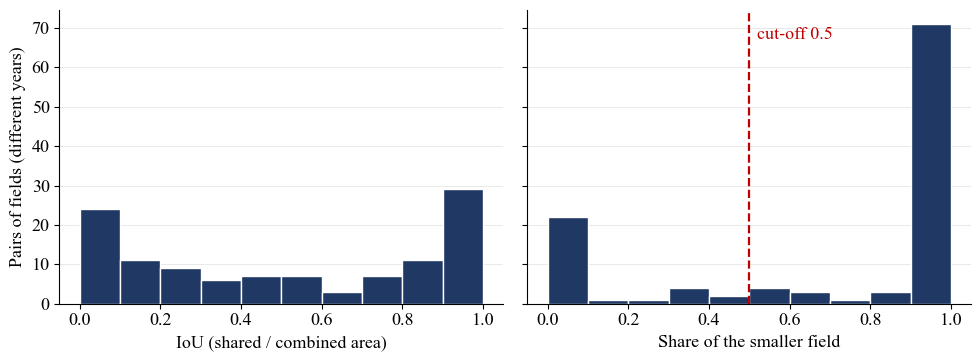

In [9]:
from scipy import stats
import matplotlib.pyplot as plt

# all pairs of fields from different years that share any land
g = f[f.geometry.notna()][["year", "geometry"]]
p = gpd.sjoin(g, g.rename(columns={"year": "year_b"}), predicate="intersects")
p = p[(p.index < p["index_right"]) & (p["year"] != p["year_b"])]
rows = []
for a, b in zip(p.index, p["index_right"]):
    ga, gb = f.geometry[a], f.geometry[b]
    inter = ga.intersection(gb).area
    if inter <= 0:
        continue
    rows.append({"i": a, "j": b, "year_a": f.at[a, "year"], "year_b": f.at[b, "year"],
                 "iou": inter / ga.union(gb).area,
                 "share_of_smaller": inter / min(ga.area, gb.area),
                 "same_farmer": f.at[a, "farmer_code"] == f.at[b, "farmer_code"],
                 "yield_a": f.at[a, "crop_yield"], "yield_b": f.at[b, "crop_yield"]})
xy = pd.DataFrame(rows)
print("pairs from different years that share land:", len(xy))

# which measure splits cleanly? count pairs in the middle (0.1 to 0.9) for each
for col in ["iou", "share_of_smaller"]:
    mid = int(xy[col].between(0.1, 0.9).sum())
    print(f"  {col:17} below 0.1: {int((xy[col] < 0.1).sum()):3} | 0.1 to 0.9: {mid:3} | above 0.9: {int((xy[col] > 0.9).sum()):3}")

# sensitivity: does the cut-off change the result?
print("\ncut-off on share_of_smaller -> pairs, same farmer, yield correlation between the two years")
for t in [0.3, 0.5, 0.7, 0.9]:
    s = xy[xy["share_of_smaller"] > t]
    r, pv = stats.pearsonr(s["yield_a"], s["yield_b"])
    print(f"  > {t}: {len(s):3} pairs | same farmer {int(s['same_farmer'].sum()):3} | r = {r:.2f} (p = {pv:.2f})")

CUT = 0.5   # in the middle of the gap; the sensitivity table shows the result does not depend on it
same = xy[xy["share_of_smaller"] > CUT]

# plot_id: fields linked as the same land across years get one ID
idx = sorted(set(same["i"]) | set(same["j"])); pos = {k: n for n, k in enumerate(idx)}
m = coo_matrix((np.ones(len(same)), ([pos[k] for k in same["i"]], [pos[k] for k in same["j"]])), shape=(len(idx), len(idx)))
_, lab = connected_components(m, directed=False)
f["plot_id"] = pd.Series({k: f"p{lab[pos[k]]:03d}" for k in idx})
f["flag_repeated_plot"] = f["plot_id"].notna()
years_per_plot = f.dropna(subset=["plot_id"]).groupby("plot_id")["year"].nunique()
print(f"\nwith cut-off {CUT}: {len(same)} pairs -> {f['plot_id'].nunique()} repeated plots, {int(f['flag_repeated_plot'].sum())} fields")
print("plots seen in 2 / 3 / 4 years:", [int((years_per_plot == k).sum()) for k in (2, 3, 4)])
xy.round(3).drop(columns=["i", "j"]).to_csv(OUT / "R3_same_land_pairs.csv", index=False)

# figure: the two measures side by side
FIG = ROOT / "reports" / "figures" / "phase1a"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, col, title in zip(axes, ["iou", "share_of_smaller"], ["IoU (shared / combined area)", "Share of the smaller field"]):
    ax.hist(xy[col], bins=np.arange(0, 1.01, 0.1), color="#1F3864", edgecolor="white")
    ax.set_xlabel(title); ax.grid(axis="y", color="#E5E5E5", lw=0.6); ax.set_axisbelow(True)
axes[1].axvline(CUT, color="#C00000", ls="--", lw=1.6)
axes[1].text(CUT + 0.02, axes[1].get_ylim()[1] * 0.9, f"cut-off {CUT}", color="#C00000")
axes[0].set_ylabel("Pairs of fields (different years)")
fig.tight_layout(); fig.savefig(FIG / "R3_same_land_overlap.png", dpi=300, facecolor="white"); plt.show()

## Step 7: All flags in one table, and save

Every check in R3 left a True/False flag column. Here we count each flag per year and save the table
with all flags, the new area (`area_acres`), the real taluka (`taluka_boundary`), `overlap_group`
and `plot_id`. A repeated plot is a tag (used later to keep plots together), not an error.
Nothing is removed: what to do with each flag is decided in R5.

**Found:** 163 of 1,207 fields have at least one geometry or location problem. The main ones:
farmer area does not match the polygon (71, batch B only), wrong taluka (46) and same-year overlap
(35, mostly 2025). Smaller ones: 2 repaired shapes, 6 with slivers removed, 4 split fields,
2 outside the district, 1 with no polygon, 1 duplicate record (2 fields). No field is tiny or huge.
160 fields sit on a repeated plot (a tag, not an error). Saved as `data/processed_v2/R3_geometry.gpkg`.

In [10]:
FLAGS = [c for c in f.columns if c.startswith("flag_")]
for c in FLAGS:
    f[c] = f[c].fillna(False).astype(bool)

summary = pd.DataFrame({
    "fields": [int(f[c].sum()) for c in FLAGS],
    **{str(y): [int(f.loc[f["year"] == y, c].sum()) for c in FLAGS] for y in sorted(f["year"].unique())},
}, index=FLAGS)
summary.to_csv(OUT / "R3_flag_summary.csv")
print(summary.to_string())
PROBLEMS = [c for c in FLAGS if c != "flag_repeated_plot"]   # a repeated plot is a tag, not an error
print("\nfields with at least one problem flag:", int(f[PROBLEMS].any(axis=1).sum()), "of", len(f),
      "| fields on a repeated plot:", int(f["flag_repeated_plot"].sum()))

# drop helper columns, keep the flags and the new area / location / group columns
keep = [c for c in f.columns if not c.startswith(("ratio_", "unit_", "within20_"))]
out = DATA2 / "R3_geometry.gpkg"
f[keep].to_file(out, driver="GPKG")
print("saved:", out, "| columns:", len(keep))

                             fields  2022  2023  2024  2025
flag_geom_repaired                2     0     0     0     2
flag_repair_changed_area          1     0     0     0     1
flag_no_polygon                   1     0     0     0     1
flag_slivers_removed              6     0     3     2     1
flag_split_field                  4     0     2     1     1
flag_tiny                         0     0     0     0     0
flag_huge                         0     0     0     0     0
flag_area_mismatch               71     7     4    60     0
flag_provider_area_negative       7     0     0     0     7
flag_outside_district             2     0     0     2     0
flag_taluka_mismatch             46     0     1    21    24
flag_overlap_same_year           35     0     0     2    33
flag_duplicate_record             2     0     0     0     2
flag_repeated_plot              160     6    16    71    67

fields with at least one problem flag: 163 of 1207 | fields on a repeated plot: 160
saved: f:\THESI

## Step 8: Map layers of the geometry problems

Saves the R3 problems as point layers for QGIS, together with the 10 taluka outlines:
area mismatch, wrong taluka, outside the district and same-year overlaps. No personal data.
We also check whether the area mismatches are packed into a few villages (a local survey problem)
or spread out.

**Found:** layers saved: 10 talukas, 71 area mismatches, 46 wrong talukas, 2 outside the district,
35 same-year overlaps. The area mismatches are spread over 32 villages; the largest share is
Bhada (14 of 54 fields, 26%), close to the overall 20%. So it is not one village or one survey.

In [11]:
LAYERS = OUT / "R3_map_layers.gpkg"
if LAYERS.exists():
    LAYERS.unlink()

pts = f[f.geometry.notna()].copy()
pts["geometry"] = pts.geometry.representative_point()
pts["farmer_vs_polygon"] = (pts["area_actual_farmer"] / pts["area_acres"]).round(2)

layers = {
    "talukas_10": talukas.rename(columns={"SUB_DIST": "taluka"}),
    "area_mismatch": pts.loc[pts["flag_area_mismatch"], ["year", "batch", "area_acres", "area_actual_farmer", "farmer_vs_polygon", "geometry"]],
    "taluka_mismatch": pts.loc[pts["flag_taluka_mismatch"], ["year", "taluka", "taluka_boundary", "geometry"]],
    "outside_district": pts.loc[pts["flag_outside_district"], ["year", "taluka", "km_outside_district", "geometry"]],
    "overlap_same_year": pts.loc[pts["flag_overlap_same_year"], ["year", "overlap_group", "flag_duplicate_record", "geometry"]],
}
for name, layer in layers.items():
    gpd.GeoDataFrame(layer, geometry="geometry", crs=UTM).to_file(LAYERS, layer=name, driver="GPKG")
    print(f"{name:18} {len(layer):4}")

# is the area mismatch spread out, or packed in a few villages?
am = f[f["area_actual_farmer"].notna()]
by_village = am.groupby("village")["flag_area_mismatch"].agg(fields="size", mismatched="sum")
by_village = by_village[by_village["mismatched"] > 0].sort_values("mismatched", ascending=False)
by_village.to_csv(OUT / "R3_area_mismatch_by_village.csv")
print(f"\narea mismatch: {int(am['flag_area_mismatch'].sum())} fields in {len(by_village)} villages; "
      f"top 3 villages hold {int(by_village['mismatched'].head(3).sum())}")
print(by_village.head(5).to_string())
print("\nsaved:", LAYERS)

talukas_10           10
area_mismatch        71
taluka_mismatch      46
outside_district      2
overlap_same_year    35

area mismatch: 71 fields in 32 villages; top 3 villages hold 24
           fields  mismatched
village                      
Bhada          54          14
Gondegaon      18           5
Sugaon         16           5
Ashta           6           3
Chata           9           3

saved: f:\THESIS\mtech_thesis_crop_yield_estimation\results\phase1a\R3_map_layers.gpkg


In [12]:
# real field outlines for the same-year overlaps (for a zoomed inset)
ovp = f.loc[f["flag_overlap_same_year"], ["year", "village", "overlap_group", "flag_duplicate_record", "crop_yield", "geometry"]]
gpd.GeoDataFrame(ovp, geometry="geometry", crs=UTM).to_file(LAYERS, layer="overlap_polygons", driver="GPKG")

# list the groups so we can pick one example
groups = ovp.groupby("overlap_group").agg(year=("year", "first"), village=("village", "first"),
                                          fields=("year", "size"), duplicate=("flag_duplicate_record", "any"))
print(groups.to_string())

               year               village  fields  duplicate
overlap_group                                               
ov000          2024             Shelu Bk.       2      False
ov001          2025               Warwada       2      False
ov002          2025              Devangra       2      False
ov003          2025              Matephal       2      False
ov004          2025             Shelu Bk.       2      False
ov005          2025  Chincholi Ballalnath       2       True
ov006          2025               Bhoyara       2      False
ov007          2025               Dhakani       2      False
ov008          2025                Mugaon       2      False
ov009          2025                  Gaur       2      False
ov010          2025                Mugaon       3      False
ov011          2025          Shivani (Ko)       2      False
ov012          2025                 Tupdi       2      False
ov013          2025               Harwadi       2      False
ov014          2025     